# Jumeau numérique — SVC

Classification de l'état des équipements avec Support Vector Classifier.

## 1. Import des bibliothèques

In [1]:
import argparse
import json
from pathlib import Path

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score, log_loss)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## 2. Collecte et affichage des données

In [2]:
dataset = pd.read_csv("digitalTwin.csv")

In [3]:
dataset.shape

(10000, 6)

In [4]:
dataset.columns

Index(['Equipment', 'HealthIndex', 'EngineTemp', 'Vibration', 'Pressure',
       'State'],
      dtype='object')

In [5]:
print(dataset.head(10).to_string(index=False))

Equipment  HealthIndex  EngineTemp  Vibration  Pressure    State
   EQ-240        90.74       67.81       3.91    292.70  Warning
    EQ-14        84.60       53.83       2.46    284.46  Warning
   EQ-270        88.32       66.18       8.93    128.07 Critical
   EQ-106        27.12       99.42       4.99    102.04  Healthy
   EQ-175        92.48      112.92       4.23    282.61 Critical
   EQ-213        11.18       51.40       7.58    174.57 Critical
    EQ-20        57.33      103.52       5.78    225.12  Warning
   EQ-150        26.98      116.54       5.29    251.24 Critical
    EQ-93        91.34      117.97       8.21    102.23  Warning
   EQ-275        76.94       68.04       9.24    114.93  Warning


In [6]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Equipment    10000 non-null  object 
 1   HealthIndex  10000 non-null  float64
 2   EngineTemp   10000 non-null  float64
 3   Vibration    10000 non-null  float64
 4   Pressure     10000 non-null  float64
 5   State        10000 non-null  object 
dtypes: float64(4), object(2)
memory usage: 468.9+ KB


In [7]:
print(dataset["State"].value_counts().rename_axis("State").to_frame("Nombre"))

          Nombre
State           
Healthy     3384
Warning     3325
Critical    3291


## 3. Nettoyage des données

In [8]:
print("Doublons :", dataset.duplicated().sum())
print(dataset.isnull().sum())

Doublons : 0
Equipment      0
HealthIndex    0
EngineTemp     0
Vibration      0
Pressure       0
State          0
dtype: int64


In [9]:
dataset = dataset.drop_duplicates()
dataset = dataset.dropna()
colonnes_numeriques = ["HealthIndex", "EngineTemp", "Vibration", "Pressure"]
dataset[colonnes_numeriques] = dataset[colonnes_numeriques].apply(pd.to_numeric, errors="coerce")
dataset = dataset.dropna(subset=colonnes_numeriques)
dataset = dataset[(dataset[colonnes_numeriques] >= 0).all(axis=1)]

In [10]:
print("Dimensions après nettoyage :", dataset.shape)
print(dataset.isnull().sum())

Dimensions après nettoyage : (10000, 6)
Equipment      0
HealthIndex    0
EngineTemp     0
Vibration      0
Pressure       0
State          0
dtype: int64


## 4. Analyse exploratoire (EDA)

In [11]:
print(dataset["HealthIndex"].describe().round(2))

count    10000.00
mean        50.16
std         28.87
min          0.00
25%         25.37
50%         50.06
75%         75.33
max         99.99
Name: HealthIndex, dtype: float64


In [12]:
print(dataset.groupby("State")[colonnes_numeriques].mean().round(2))

          HealthIndex  EngineTemp  Vibration  Pressure
State                                                 
Critical        50.25       84.79       5.09    225.94
Healthy         50.38       85.45       5.00    224.57
Warning         49.84       85.02       5.05    224.74


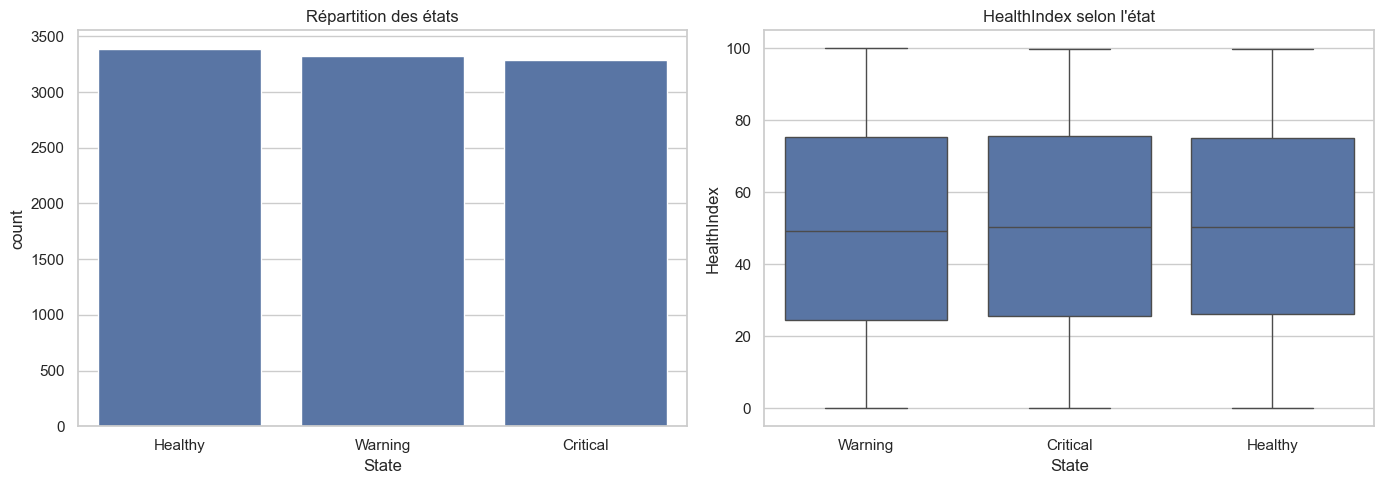

In [13]:
sns.set_theme(style="whitegrid")
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=dataset, x="State", order=dataset["State"].value_counts().index, ax=axes[0])
axes[0].set_title("Répartition des états")
sns.boxplot(data=dataset, x="State", y="HealthIndex", ax=axes[1])
axes[1].set_title("HealthIndex selon l'état")
figure.tight_layout()
display(figure)
plt.close(figure)

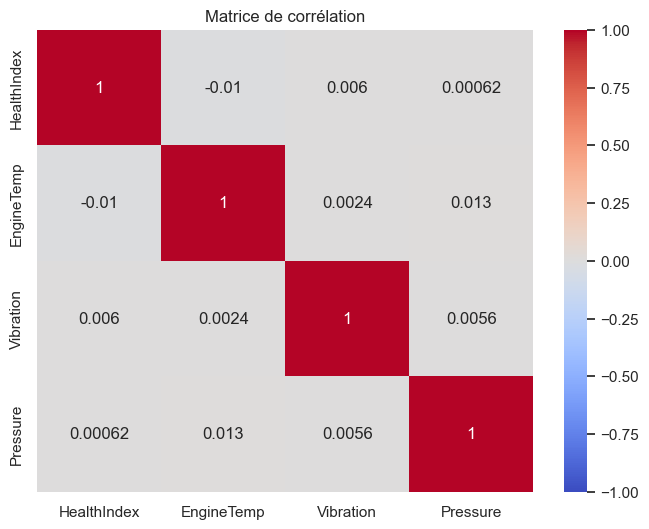

In [14]:
correlations = dataset[colonnes_numeriques].corr()
figure, axe = plt.subplots(figsize=(8, 6))
sns.heatmap(correlations, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axe)
axe.set_title("Matrice de corrélation")
display(figure)
plt.close(figure)

## 5. Ingénierie des caractéristiques

In [15]:
dataset["TempVibration"] = dataset["EngineTemp"] * dataset["Vibration"]
dataset["PressureVibrationRatio"] = dataset["Pressure"] / (dataset["Vibration"] + 0.01)
dataset["HealthRisk"] = 100 - dataset["HealthIndex"]

In [16]:
features = ["HealthIndex", "EngineTemp", "Vibration", "Pressure", "TempVibration", "PressureVibrationRatio", "HealthRisk"]
X = dataset[features]
y = dataset["State"]

In [17]:
print(X.head())
print(y.value_counts())

   HealthIndex  EngineTemp  Vibration  Pressure  TempVibration  \
0        90.74       67.81       3.91    292.70       265.1371   
1        84.60       53.83       2.46    284.46       132.4218   
2        88.32       66.18       8.93    128.07       590.9874   
3        27.12       99.42       4.99    102.04       496.1058   
4        92.48      112.92       4.23    282.61       477.6516   

   PressureVibrationRatio  HealthRisk  
0               74.668367        9.26  
1              115.165992       15.40  
2               14.325503       11.68  
3               20.408000       72.88  
4               66.653302        7.52  
State
Healthy     3384
Warning     3325
Critical    3291
Name: count, dtype: int64


## 6. Entraînement du modèle SVC

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [19]:
modele_svc = Pipeline([("normalisation", StandardScaler()), ("svc", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, class_weight="balanced", random_state=42))])

In [20]:
modele_svc.fit(X_train, y_train)

,steps,"[('normalisation', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'


In [21]:
joblib.dump(modele_svc, "svc_state_model.joblib")

['svc_state_model.joblib']

## 7. Évaluation du modèle

In [22]:
predictions = modele_svc.predict(X_test)
probabilites = modele_svc.predict_proba(X_test)

In [23]:
print("Accuracy SVC :", round(accuracy_score(y_test, predictions), 4))
print("F1 pondéré SVC :", round(f1_score(y_test, predictions, average="weighted"), 4))
print("Log loss SVC :", round(log_loss(y_test, probabilites, labels=modele_svc.classes_), 4))
print(classification_report(y_test, predictions))

Accuracy SVC : 0.326
F1 pondéré SVC : 0.3258
Log loss SVC : 1.0989
              precision    recall  f1-score   support

    Critical       0.31      0.30      0.31       658
     Healthy       0.34      0.35      0.34       677
     Warning       0.32      0.32      0.32       665

    accuracy                           0.33      2000
   macro avg       0.33      0.33      0.33      2000
weighted avg       0.33      0.33      0.33      2000



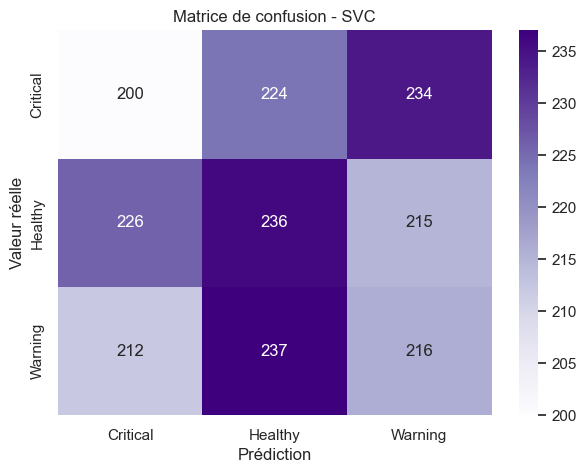

In [24]:
matrice = confusion_matrix(y_test, predictions, labels=modele_svc.classes_)
figure, axe = plt.subplots(figsize=(7, 5))
sns.heatmap(matrice, annot=True, fmt="d", cmap="Purples", xticklabels=modele_svc.classes_, yticklabels=modele_svc.classes_, ax=axe)
axe.set_xlabel("Prédiction"); axe.set_ylabel("Valeur réelle"); axe.set_title("Matrice de confusion - SVC")
display(figure)
plt.close(figure)

In [25]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Accuracy baseline :", round(accuracy_score(y_test, baseline.predict(X_test)), 4))

Accuracy baseline : 0.3385
